In [2]:
import pandas as pd

#第一问

# 读取数据
df = pd.read_csv('ibtracs.ALL.list.v04r00.csv',
                 usecols=range(17),  #只使用前17列
                 skiprows=[1, 2],  #NOAA 的这类文件，第一行是列名，第二行是单位, 数据分析需要跳过
                 parse_dates=['ISO_TIME'],  #
                 na_values=[' NOT_NAMED', ' NAME'])

# 剔除 WMO_WIND 缺失的行,防止 NaN 影响最大值判断
df_clean = df.dropna(subset=['WMO_WIND'])

# 按 SID 分组，对 NAME 取第一个（因为同一个 SID 名字一样），对 WMO_WIND 取最大值, agg() 函数可以同时对不同的列应用不同的操作，以保留多列的返回结果
largest_hurricanes = df_clean.groupby('SID').agg({
    'NAME': 'first',        # 提取该飓风的名字
    'WMO_WIND': 'max'       # 提取该飓风经历的最大风速
})

# 按最大风速降序排序，并取前 10 名
top10_hurricanes = largest_hurricanes.sort_values(by='WMO_WIND', ascending=False).head(10)

# 打印结果
print(top10_hurricanes)

                         NAME WMO_WIND
SID                                   
1997125S08079          RHONDA       95
2005237N14148           TALIM       95
2005054S09173           PERCY       95
2005063S12141          INGRID       95
2005092S11102  ADELINE:JULIET       95
2005148N06156           NESAT       95
2005192N11318           EMILY       95
2005192N22155         HAITANG       95
2005230N20144           MAWAR       95
2005236N23285         KATRINA       95


In [3]:
#第二问

# 基于之前清洗好的 df_clean ，即已经去除了风速为空的记录，按 SID 分组，获取每个飓风的名字和它在生命周期内的最大风速
strongest_hurricanes = df_clean.groupby('SID').agg({
    'NAME': 'first',       # 取飓风的名字，保留第一个
    'WMO_WIND': 'max'      # 提取该飓风经历过的最大风速
}).reset_index()           # 将 SID 从索引还原成普通列，方便后续查看

# 2. 按照最大风速（WMO_WIND）降序排列，ascending=False 表示从大到小排
top20_hurricanes = strongest_hurricanes.sort_values(by='WMO_WIND', ascending=False).head(20)

# 3.列出风速 (WMO_WIND)
print(top20_hurricanes[['SID', 'NAME', 'WMO_WIND']].to_string(index=False))


          SID           NAME WMO_WIND
1997125S08079         RHONDA       95
2005237N14148          TALIM       95
2005054S09173          PERCY       95
2005063S12141         INGRID       95
2005092S11102 ADELINE:JULIET       95
2005148N06156          NESAT       95
2005192N11318          EMILY       95
2005192N22155        HAITANG       95
2005230N20144          MAWAR       95
2005236N23285        KATRINA       95
1906281N11284      NOT_NAMED       95
2005241N15155           NABI       95
2006074S13158          LARRY       95
1906263N12283      NOT_NAMED       95
2005255N15246           JOVA       95
1906238N14339      NOT_NAMED       95
2005261N21290           RITA       95
2005268N19146       LONGWANG       95
2005282N22138         KIROGI       95
2005289N18282          WILMA       95


In [5]:
#第三问
# 按 'Basin' 列分组，使用 .size() 统计每个分组的行数，统计完分组行数后，新建Data_Points列作为索引
basin_counts = df.groupby('BASIN').size().reset_index(name='Data_Points')

# 按照数据点个数从大到小降序排列，查看哪个海域的数据最多
basin_counts = basin_counts.sort_values(by='Data_Points', ascending=False)

# 3. 打印结果
print(basin_counts.to_string(index=False))

BASIN  Data_Points
   WP       236576
   SI       160668
   SP        67119
   EP        62412
   NI        55401
   SA          119


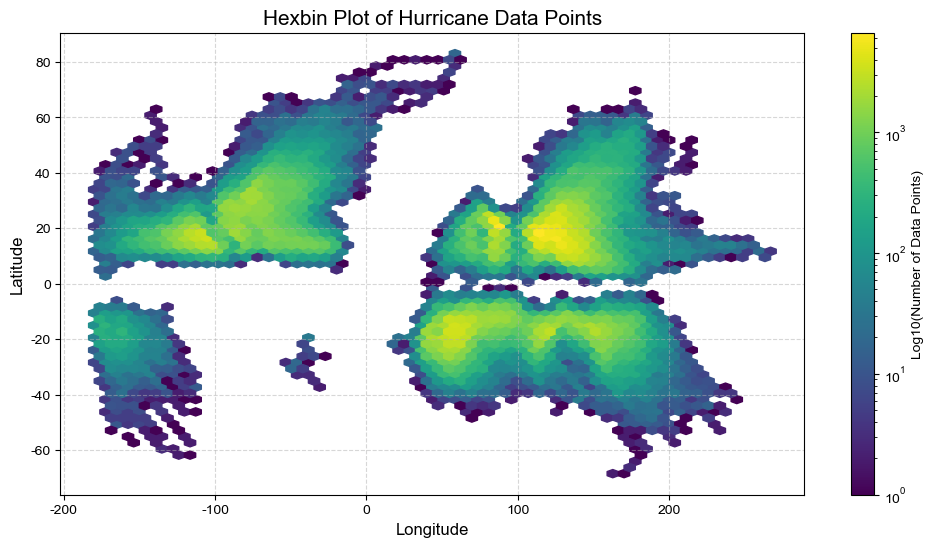

In [7]:
#第四问
import pandas as pd
import matplotlib.pyplot as plt

# 数据预处理：提取经纬度，并确保它们是数值型，过滤掉缺失值
# 原始数据中的 LAT 和 LON 可能被读成了字符串或者包含 NaN
plot_df = df.dropna(subset=['LAT', 'LON']).copy()
plot_df['LAT'] = pd.to_numeric(plot_df['LAT'], errors='coerce')
plot_df['LON'] = pd.to_numeric(plot_df['LON'], errors='coerce')
plot_df = plot_df.dropna(subset=['LAT', 'LON']) # 再次清理转换时产生的 NaN

# 设置画布大小
plt.figure(figsize=(12, 6))

# 绘制 Hexbin 图
# x 轴为经度 (LON)，y 轴为纬度 (LAT)
# gridsize=50 表示划分成 50x50 的六边形网格，数值越大网格越细
hb = plt.hexbin(plot_df['LON'], plot_df['LAT'], 
                gridsize=60, 
                cmap='viridis',  #是一种颜色映射，点越密颜色越亮（变黄）
                mincnt=1,  #表示只显示至少有 1 个数据点的六边形，避免地图全黑
                bins='log') # 使用对数尺度，让分布不那么极端的地方也能看清

# 添加颜色条（Colorbar）
# 用来解释颜色深浅代表的数据点数量
cb = plt.colorbar(hb)
cb.set_label('Log10(Number of Data Points)')

# 设置标题和标签
plt.title('Hexbin Plot of Hurricane Data Points', fontsize=15)
plt.xlabel('Longitude', fontsize=12)
plt.ylabel('Latitude', fontsize=12)

# 设置网格线
plt.grid(True, linestyle='--', alpha=0.5)

# 显示图表
plt.show()

In [ ]:
!pip install cartopy

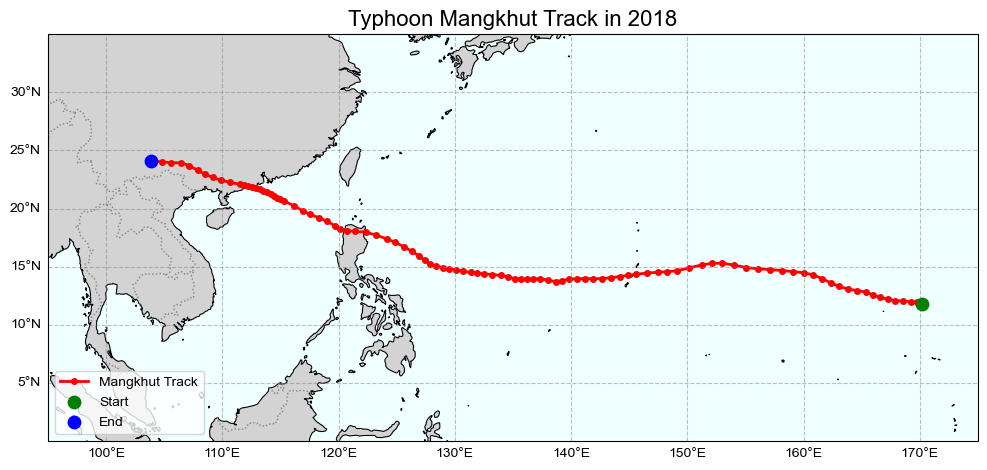

In [14]:

#第五问

import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature  #绘制地图的库
import pandas as pd

# 1. 筛选山竹数据
mangkhut = df[(df['NAME'] == 'MANGKHUT') & (df['SEASON'] == 2018)].copy()  #求和筛选
mangkhut['LON'] = pd.to_numeric(mangkhut['LON'], errors='coerce')
mangkhut['LAT'] = pd.to_numeric(mangkhut['LAT'], errors='coerce')
mangkhut = mangkhut.dropna(subset=['LON', 'LAT']).sort_values(by='ISO_TIME') #按时间顺序排序，按时间先后连线，按照时间就是默认的升序

# 2. 设置地图投影，世界大洲使用等距圆柱投影
fig = plt.figure(figsize=(12, 8))
ax = plt.axes(projection=ccrs.PlateCarree())

# 3.添加海岸线和陆地颜色
ax.add_feature(cfeature.LAND, facecolor='lightgray')  # 陆地
ax.add_feature(cfeature.OCEAN, facecolor='azure')     # 海洋
ax.add_feature(cfeature.COASTLINE, edgecolor='black', linewidth=0.8) # 海岸轮廓线
ax.add_feature(cfeature.BORDERS, linestyle=':', edgecolor='gray')    # 国家边界

# 4. 限定地图的显示范围，经度范围大概在东经 90 到 170，纬度在北纬 0 到 35
ax.set_extent([95, 175, 0, 35], crs=ccrs.PlateCarree())

# 5. 绘制台风轨迹，使用 cartopy 的坐标系时，必须加上 transform=ccrs.PlateCarree()
ax.plot(mangkhut['LON'], mangkhut['LAT'], 
        marker='o', linestyle='-', color='red', linewidth=2, markersize=4,
        transform=ccrs.PlateCarree(), label='Mangkhut Track')

# 标记起点和终点
start_lon, start_lat = mangkhut['LON'].iloc[0], mangkhut['LAT'].iloc[0]
end_lon, end_lat = mangkhut['LON'].iloc[-1], mangkhut['LAT'].iloc[-1]
ax.scatter(start_lon, start_lat, color='green', s=80, label='Start', zorder=5, transform=ccrs.PlateCarree())
ax.scatter(end_lon, end_lat, color='blue', s=80, label='End', zorder=5, transform=ccrs.PlateCarree())

# 添加经纬度网格线
gl = ax.gridlines(draw_labels=True, linestyle='--', color='gray', alpha=0.5)
gl.top_labels = False   # 隐藏顶部经度标签
gl.right_labels = False # 隐藏右侧纬度标签

# 8. 标题和图例
plt.title('Typhoon Mangkhut Track in 2018', fontsize=16)
plt.legend(loc='lower left')

# 显示图表
plt.show()

In [15]:
#第六问
# 筛选数据：年份 >= 1970，并且 Basin 包含 'WP' 或 'EP'，将筛选结果复制到一个新的表格里，dataframe
df_filtered = df[(df['SEASON'] >= 1970) & (df['BASIN'].isin(['WP', 'EP']))].copy()

# 2. 打印一下新表格的形状，确认筛选成功
print(f"行数: {df_filtered.shape[0]}")
print(f"范围: {df_filtered['SEASON'].min()} 到 {df_filtered['SEASON'].max()}")
print(f"包含的海域: {df_filtered['BASIN'].unique()}")


行数: 176352
范围: 1970 到 2022
包含的海域: <StringArray>
['WP', 'EP']
Length: 2, dtype: str


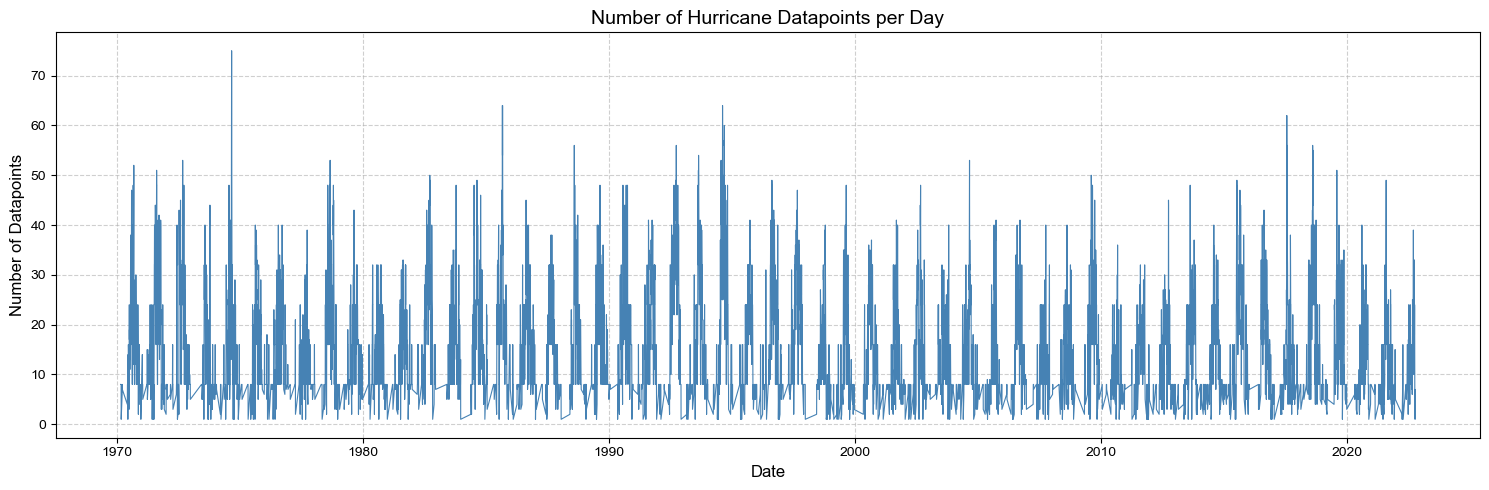

In [16]:
#第七问
import matplotlib.pyplot as plt
import pandas as pd

# 提取日期部分，按天统计行数，将时间列转为纯日期格式，然后使用 value_counts() 统计每天的记录数，会把分组的依据变成索引，.sort_index()按照索引的先后顺序排，即时间的先后
daily_counts = df_filtered['ISO_TIME'].dt.date.value_counts().sort_index()

plt.figure(figsize=(15, 5))

# 画折线图，X轴是日期，Y轴是每天的记录数
plt.plot(daily_counts.index, daily_counts.values, color='steelblue', linewidth=0.8)

# 设置标题和标签
plt.title('Number of Hurricane Datapoints per Day', fontsize=14)
plt.xlabel('Date', fontsize=12)
plt.ylabel('Number of Datapoints', fontsize=12)

# 设置网格线
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

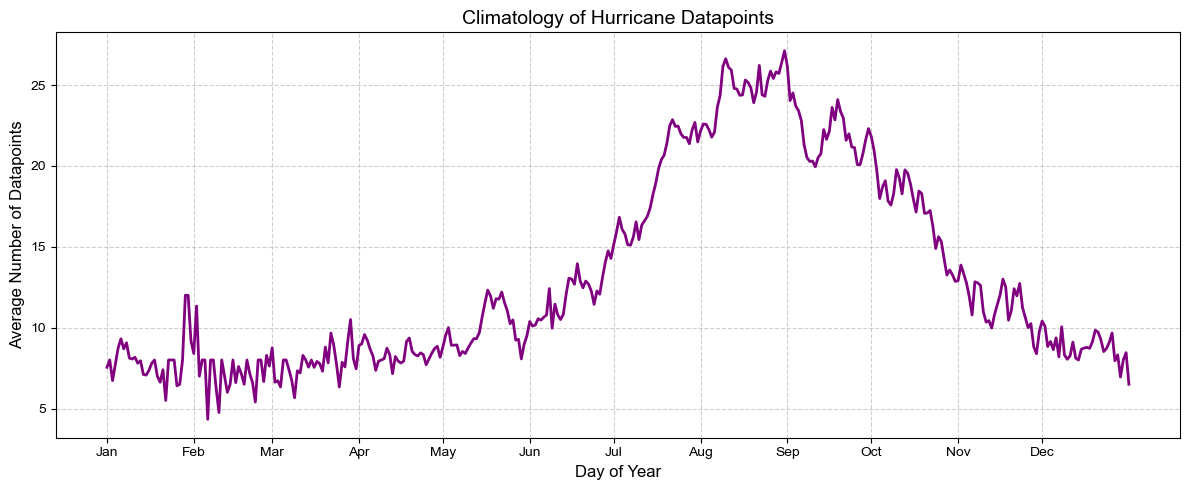

In [17]:
#第八问

import pandas as pd
import matplotlib.pyplot as plt

# datetime 格式
df_filtered['ISO_TIME'] = pd.to_datetime(df_filtered['ISO_TIME'])

# 2. 提取年份 (Year) 和一年中的第几天 (DOY: Day of Year, 1-366),.dt.dayofyear 会自动处理闰年
df_filtered['Year'] = df_filtered['ISO_TIME'].dt.year
df_filtered['DOY'] = df_filtered['ISO_TIME'].dt.dayofyear

# 统计每年每天的数据点数量,groupby(['Year', 'DOY']) 把每年的每一天分成一组，.size() 数这一天有几条记录，将记录这一列命名成Count
daily_counts = df_filtered.groupby(['Year', 'DOY']).size().reset_index(name='Count')

# 4. 计算气候态（多年平均），按 DOY 分组，对 Count 求平均，这时会生成一个一维序列，DOY是索引，.reset_index()即转成dataframe
climatology = daily_counts.groupby('DOY')['Count'].mean().reset_index()

# 5. 画图展示气候态
plt.figure(figsize=(12, 5))

# X轴为 1 到 366 天，Y轴为平均数量
plt.plot(climatology['DOY'], climatology['Count'], color='purple', linewidth=2)

# 设置标题和标签
plt.title('Climatology of Hurricane Datapoints', fontsize=14)
plt.xlabel('Day of Year', fontsize=12)
plt.ylabel('Average Number of Datapoints', fontsize=12)

# 设置网格线
plt.grid(True, linestyle='--', alpha=0.6)

#美化X轴，更清晰
month_starts = [1, 32, 60, 91, 121, 152, 182, 213, 244, 274, 305, 335]
month_labels = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
plt.xticks(month_starts, month_labels)

plt.tight_layout()
plt.show()

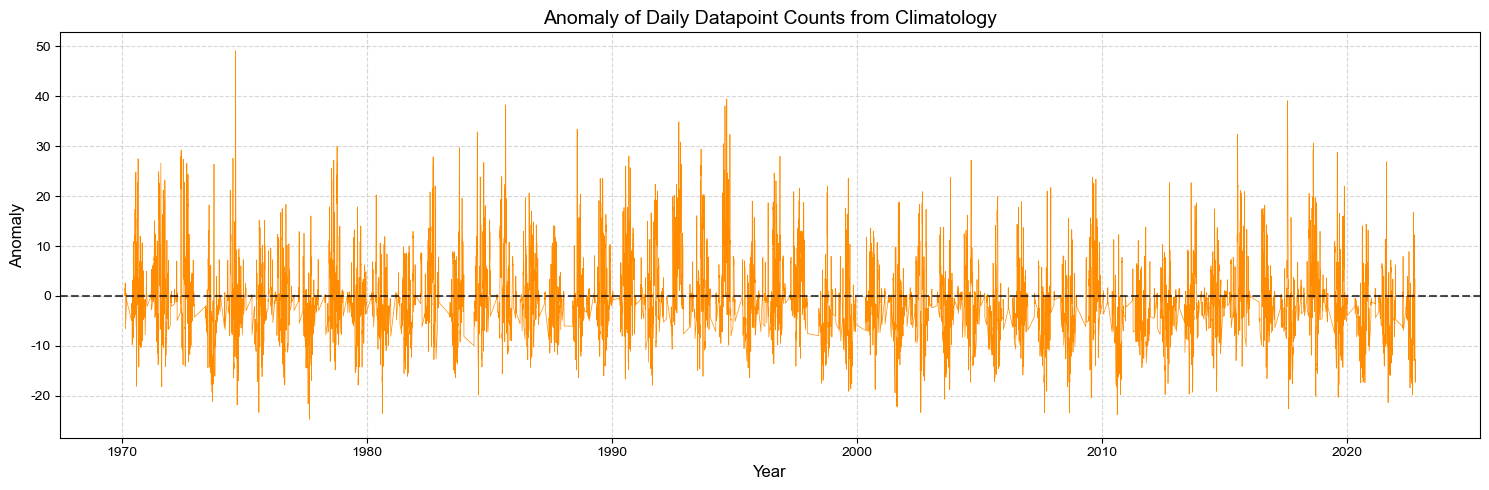

In [18]:
#第九问

import pandas as pd
import matplotlib.pyplot as plt

# 让列名冲突，先把 climatology 里的 'Count' 改名叫 'Clim_Mean'
clim_renamed = climatology.rename(columns={'Count': 'Clim_Mean'})

# 合并表格：以 'DOY'为基准，把气候态均值拼接到每日实际数据旁边
merged_df = pd.merge(daily_counts, clim_renamed, on='DOY', how='left')

# 计算异常值：实际的 Count减去平均的 Clim_Mean
merged_df['Anomaly'] = merged_df['Count'] - merged_df['Clim_Mean']

merged_df['Date'] = pd.to_datetime(merged_df['Year'].astype(str) + '-' + merged_df['DOY'].astype(str), format='%Y-%j')

# 开始画图
plt.figure(figsize=(15, 5))
plt.plot(merged_df['Date'], merged_df['Anomaly'], color='darkorange', linewidth=0.5)

#y=0 的水平参考线
plt.axhline(y=0, color='black', linestyle='--', linewidth=1.5, alpha=0.7)

plt.title('Anomaly of Daily Datapoint Counts from Climatology', fontsize=14)
plt.xlabel('Year', fontsize=12)
plt.ylabel('Anomaly', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

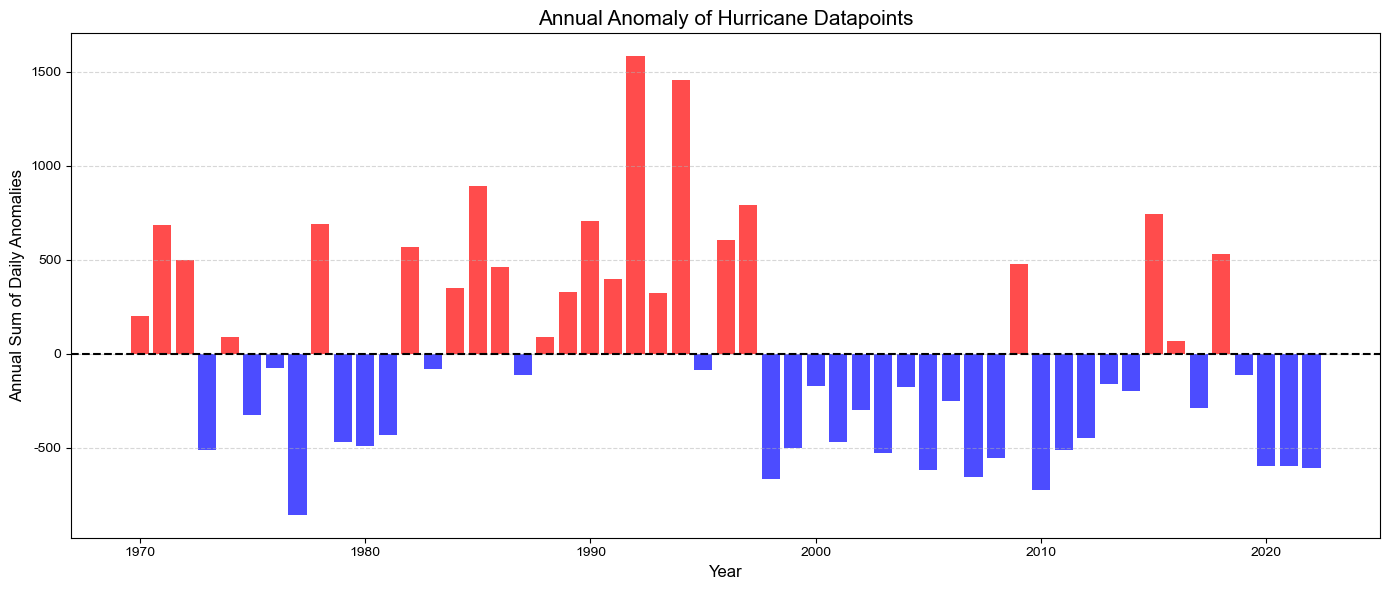

飓风最活跃5年：
Date
1992-12-31    1582.532875
1994-12-31    1455.546754
1985-12-31     893.650437
1997-12-31     789.172554
2015-12-31     743.696427

飓风最安静5年：
Date
1977-12-31   -855.355915
2010-12-31   -725.193184
1998-12-31   -665.903610
2007-12-31   -653.054365
2005-12-31   -617.024423


In [19]:
#第十问

import pandas as pd
import matplotlib.pyplot as plt

#将 Date 列设置为索引，以便使用 resample 功能
merged_df.set_index('Date', inplace=True)

# 2. 将每日异常值重采样到年度（Annual）
annual_anomaly = merged_df['Anomaly'].resample('YE').sum()  #YE代表 Year End，会按自然年把数据分组，再分组求和，求和后是一个一维序列，年份是索引，值是求和后的

# 3. 绘图
plt.figure(figsize=(14, 6))

# 画柱状图：正值为红色，负值为蓝色
colors = ['red' if val > 0 else 'blue' for val in annual_anomaly.values]  #val是临时变量名称，代表values里的数字
plt.bar(annual_anomaly.index.year, annual_anomaly.values, color=colors, alpha=0.7)

# y=0基准线
plt.axhline(y=0, color='black', linestyle='--', linewidth=1.5)

plt.title('Annual Anomaly of Hurricane Datapoints', fontsize=15)
plt.xlabel('Year', fontsize=12)
plt.ylabel('Annual Sum of Daily Anomalies', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5, axis='y') #沿着y轴画虚线

plt.tight_layout()
plt.show()

print("飓风最活跃5年：")
print(annual_anomaly.nlargest(5).to_string())

print("\n飓风最安静5年：")
print(annual_anomaly.nsmallest(5).to_string())